# Evaluation on Pascal VOC 2012

Runs the pipeline with several saliency methods (LayerCAM, GradCAM and LRP variants) on Pascal VOC images
that contain a single object class, and compares the selected segmentation with the ground truth.
Three reference points use the same SAM masks: two baselines without a saliency map (the largest and the
center mask) and an upper bound that picks SAM's masks with the ground truth.

This notebook runs a small sample; `scripts/benchmark.py` runs all images (about 2.5 hours) and the last
section summarizes its results.

Needs Pascal VOC 2012 in `datasets/VOCSegmentation` (set `DOWNLOAD = True` once, about 2 GB).

In [1]:
import random

import numpy as np
import pandas as pd
import torch

from image_subject_selection import load_resnet, load_sam, plotting
from image_subject_selection.evaluation import (RESULTS_DIR, Evaluator, default_metrics, default_xai_methods, label_table,
                                     load_pascal_voc, save_results, single_class_images)

DOWNLOAD = False
N_SAMPLES = 5
SEED = 123

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

sam = load_sam("vit_b")  # the original evaluation used vit_h (scripts/download_checkpoints.sh --vit-h)
resnet = load_resnet()

## Dataset

Train and val sets, center-cropped to squares. Only images with exactly one class, without classes that ImageNet has no counterpart for.

reading masks:   0%|          | 0/2913 [00:00<?, ?it/s]

1509 of 2913 images


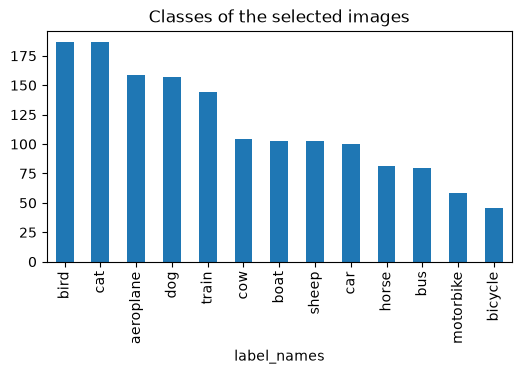

In [2]:
pascal = load_pascal_voc(download=DOWNLOAD)
labels = label_table(pascal)
candidates = single_class_images(labels)
print(f"{len(candidates)} of {len(pascal)} images")
candidates["label_names"].explode().value_counts().plot(kind="bar", figsize=(6, 3), title="Classes of the selected images");

## Saliency methods and metrics

EP = LRP with the Epsilon-Plus rule, GB = Epsilon-Gamma-Box; with a layer name the relevance is taken at that
layer instead of the input. See `image_subject_selection.evaluation.default_xai_methods` and `default_metrics`.

In [3]:
xai_methods = default_xai_methods(resnet)
metrics = default_metrics()
list(xai_methods)

['LayerCAM',
 'GradCAM',
 'EP',
 'EP 1.0.conv2',
 'EP 2.0.conv2',
 'EP 3.0.conv2',
 'GB',
 'GB 1.0.conv2',
 'GB 2.0.conv2',
 'GB 3.0.conv2']

## Run on a sample

Per image and method: the selection (gray), the saliency map (red/yellow, not for the reference points) and the
ground truth outline (green).

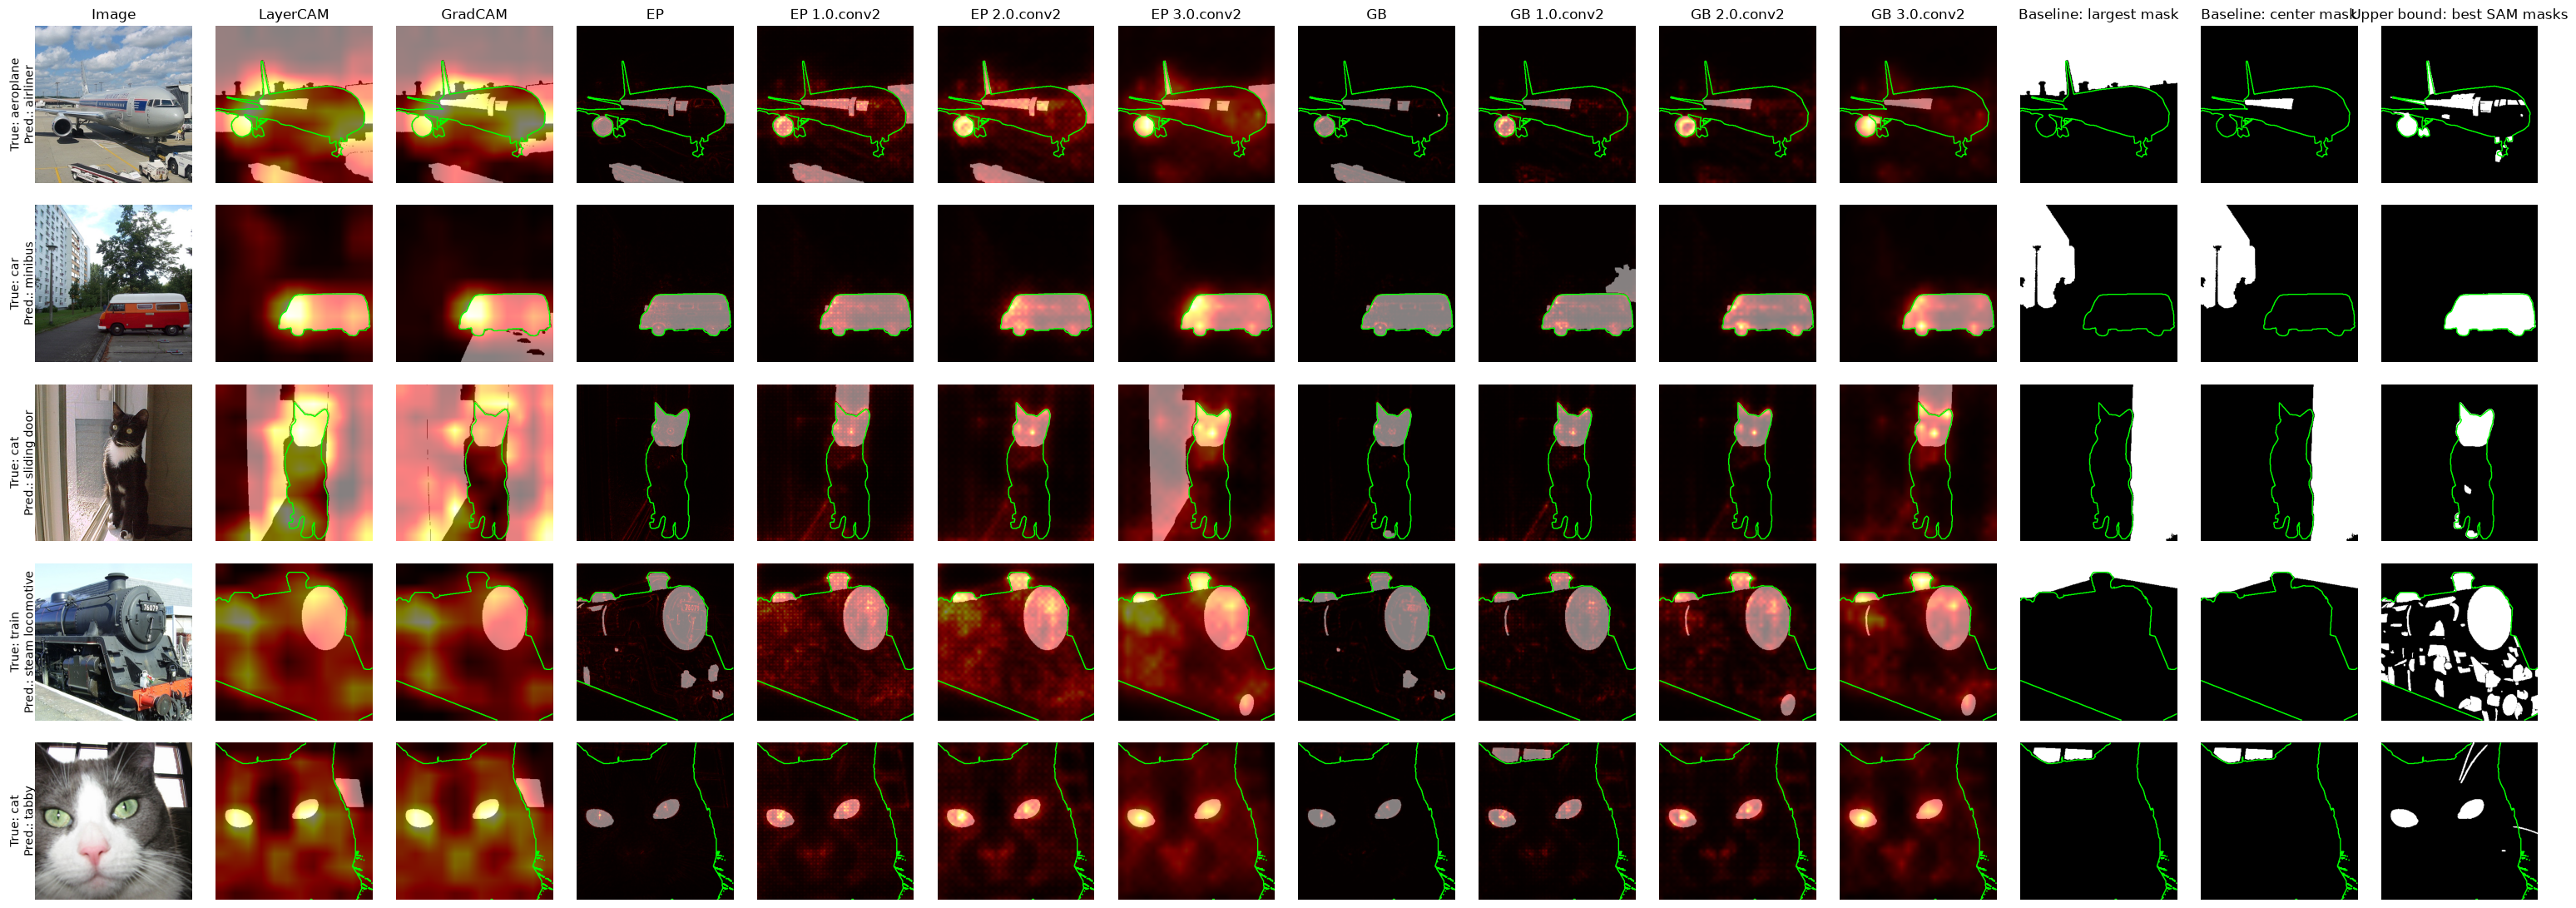

In [4]:
evaluator = Evaluator(resnet, sam, xai_methods, metrics)
sample = random.sample(list(candidates["dataset_idx"]), N_SAMPLES)

outputs = [evaluator(*pascal[idx], idx) for idx in sample]
plotting.evaluation_grid(outputs);

In [5]:
COLUMNS = ["iou", "dice", "precision", "recall", "biou"]
results = evaluator.results
results.groupby("xai_method")[COLUMNS].mean().sort_values("iou", ascending=False)

,iou,dice,precision,recall,biou
xai_method,,,,,
Upper bound: best SAM masks,0.396698,0.506412,0.952867,0.405035,0.198145
EP,0.318061,0.407772,0.858237,0.333054,0.164938
GB,0.316315,0.404793,0.875968,0.328445,0.169505
EP 2.0.conv2,0.314937,0.402008,0.862621,0.330571,0.189166
GB 2.0.conv2,0.312888,0.400395,0.975524,0.320076,0.167709
GB 3.0.conv2,0.306207,0.390080,0.885139,0.321306,0.170884
EP 1.0.conv2,0.302606,0.385876,0.778591,0.326260,0.172074
EP 3.0.conv2,0.291298,0.367932,0.746537,0.329382,0.188405
GB 1.0.conv2,0.276681,0.376885,0.853962,0.317431,0.167284


In [6]:
print("saved:", save_results(results, "pascal_voc_sample"))

saved: /home/jovyan/Documents/personal/image-subject-selection/results/pascal_voc_sample_2026-11-15_15-10-29.csv


## Whole dataset

`uv run python scripts/benchmark.py` evaluates all suitable images (about 2.5 hours with SAM ViT-B on one GPU)
and writes `results/pascal_voc_vit_b_<timestamp>.csv`. The newest such file:

In [7]:
full_runs = sorted(RESULTS_DIR.glob("pascal_voc_vit_*.csv"))
if full_runs:
    full = pd.read_csv(full_runs[-1])
    print(full_runs[-1].name, "-", full["dataset_idx"].nunique(), "images")
    display(full.groupby("xai_method")[COLUMNS].mean().sort_values("iou", ascending=False).round(3))
else:
    print("no full run in", RESULTS_DIR)

no full run in /home/jovyan/Documents/personal/image-subject-selection/results
